<a href="https://colab.research.google.com/github/mvaishnavi2007/ITA0520---CV/blob/main/EXP_13_AFFINE_TRANSFORMATION.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

In [3]:
uploaded = files.upload()

Saving Screenshot 2026-11-11 103837.png to Screenshot 2026-11-11 103837.png


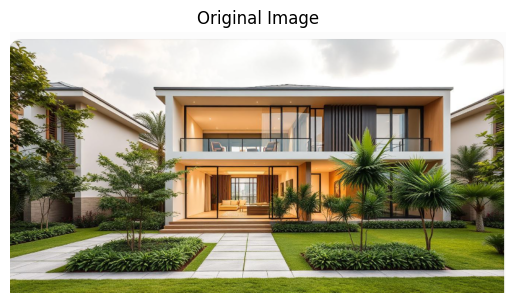

In [4]:
filename = list(uploaded.keys())[0]

img = cv2.imdecode(
    np.frombuffer(uploaded[filename], np.uint8),
    cv2.IMREAD_COLOR
)

if img is None:
    raise ValueError("Please upload a valid image.")

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.imshow(img_rgb)
plt.title("Original Image")
plt.axis("off")
plt.show()

In [5]:
height, width = img.shape[:2]

pts1 = np.float32([
    [0, 0],
    [width - 1, 0],
    [0, height - 1]
])

pts2 = np.float32([
    [width * 0.1, height * 0.1],
    [width * 0.9, height * 0.2],
    [width * 0.2, height * 0.9]
])

print("Original points:")
print(pts1)

print("Destination points:")
print(pts2)

Original points:
[[  0.   0.]
 [800.   0.]
 [  0. 421.]]
Destination points:
[[ 80.1  42.2]
 [720.9  84.4]
 [160.2 379.8]]


In [6]:
matrix = cv2.getAffineTransform(pts1, pts2)

transformed = cv2.warpAffine(
    img,
    matrix,
    (width, height)
)

print("Affine transformation completed")

Affine transformation completed


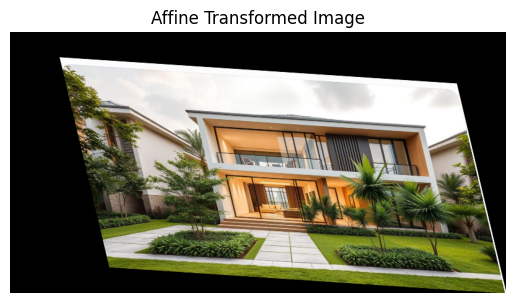

In [7]:
transformed_rgb = cv2.cvtColor(
    transformed, cv2.COLOR_BGR2RGB
)

plt.imshow(transformed_rgb)
plt.title("Affine Transformed Image")
plt.axis("off")
plt.show()

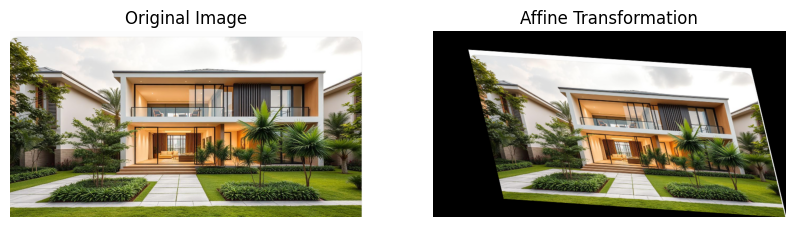

In [8]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(transformed_rgb)
plt.title("Affine Transformation")
plt.axis("off")

plt.show()

In [9]:
cv2.imwrite("affine_image.jpg", transformed)
files.download("affine_image.jpg")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>